# LSTM stock price forecasting (Reliance Industries, NSE)
Univariate LSTM on daily closing prices: 120-day look-back window, MinMax scaling, chronological 80/20 split. Test RMSE **35.9 INR**. Data: Yahoo Finance `RELIANCE.NS` daily history (download the CSV and upload it to Colab).

*Educational exercise, not investment advice.*

         Date       Open       High        Low    Close  Adj Close      Volume
0  1996-01-01  16.009800  16.095699  15.904300  16.0683   2.422041  47600787.0
1  1996-01-02  16.029301  16.107401  15.826200  15.9434   2.403215  77143764.0
2  1996-01-03  16.205000  16.943001  16.029301  16.0644   2.421453  95695836.0
3  1996-01-04  15.912100  15.962900  15.701300  15.9160   2.399085  99159504.0
4  1996-01-05  15.853600  15.853600  15.670000  15.8067   2.382609  76213503.0

Dataset Shape After Cleaning: (6164, 1)

Shape of X: (6044, 120)
Shape of y: (6044,)

X_train Shape: (4835, 120, 1)
X_test Shape : (1209, 120, 1)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_15 (LSTM)                  │ (None, 120, 100)       │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ (None, 120, 60)        │        38,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 20)             │         6,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘


 Total params: 85,941 (335.71 KB)


 Trainable params: 85,941 (335.71 KB)


 Non-trainable params: 0 (0.00 B)


Epoch 1/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 31s 210ms/step - loss: 7.3353e-04 - val_loss: 6.7896e-05
Epoch 2/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 24s 196ms/step - loss: 8.1030e-05 - val_loss: 8.0787e-05
Epoch 3/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 22s 180ms/step - loss: 7.9157e-05 - val_loss: 8.1332e-05
Epoch 4/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 43s 201ms/step - loss: 7.5386e-05 - val_loss: 5.7616e-05
Epoch 5/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 40s 194ms/step - loss: 7.0082e-05 - val_loss: 1.0040e-04
Epoch 6/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 25s 205ms/step - loss: 7.0177e-05 - val_loss: 6.0308e-05
Epoch 7/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 24s 200ms/step - loss: 5.9162e-05 - val_loss: 5.8921e-05
Epoch 8/50
... (output truncated) ...
121/121 ━━━━━━━━━━━━━━━━━━━━ 25s 208ms/step - loss: 2.4654e-05 - val_loss: 1.4650e-05
Epoch 45/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 24s 195ms/step - loss: 2.3284e-05 - val_loss: 1.5749e-05
Epoch 46/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 43s 210ms/step - loss: 2.2299e-05 - val_loss: 1.4420e-05
E

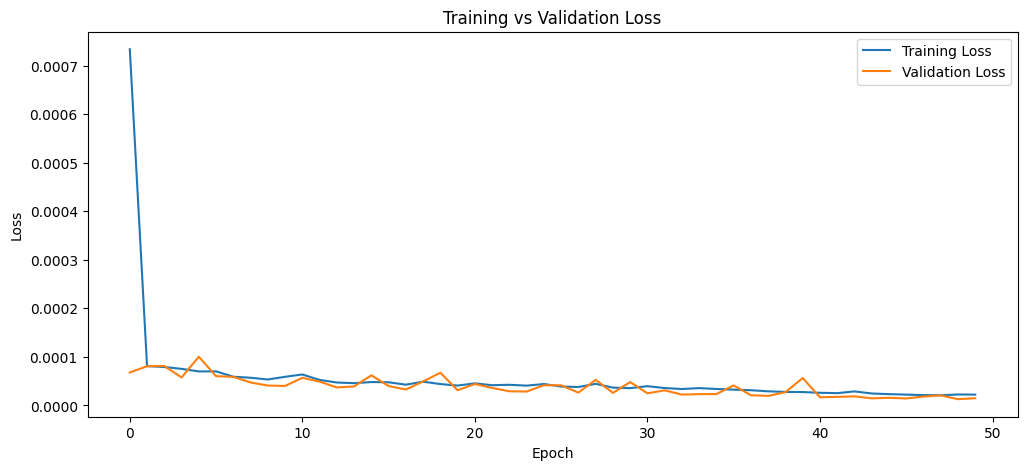

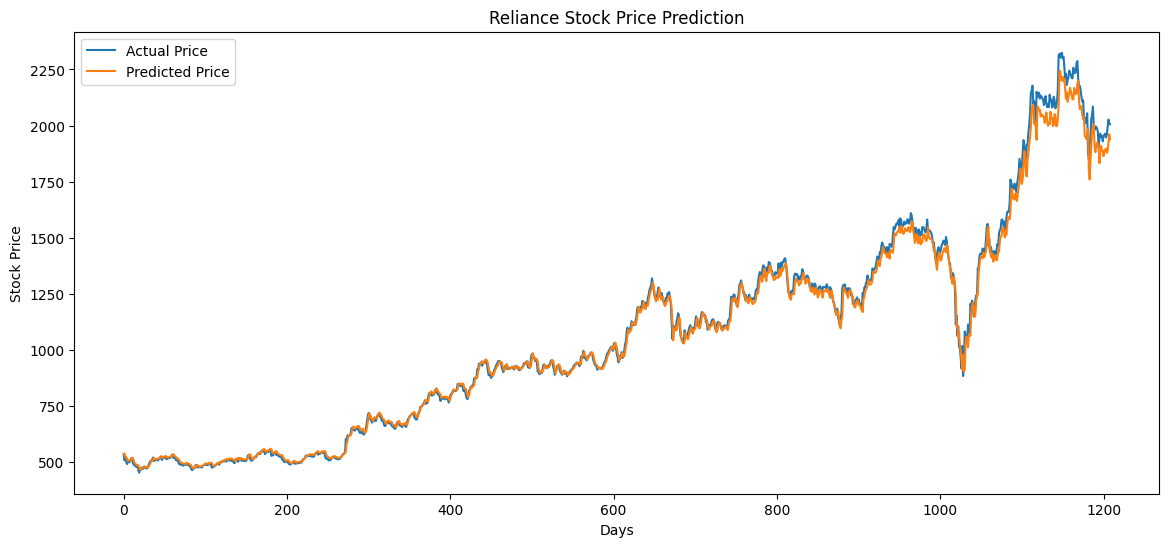

In [7]:
# ============================================================
# LSTM Stock Price Prediction - Reliance Stock
# FULL UPDATED WORKING CODE
# Google Colab Ready
# ============================================================

# ============================================================
# INSTALL REQUIRED LIBRARIES
# ============================================================

!pip install -q tensorflow pandas numpy matplotlib scikit-learn

# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

# ============================================================
# LOAD DATASET
# ============================================================

# Upload RELIANCE.NS.csv before running

df = pd.read_csv('/content/RELIANCE.NS.csv')

# Show first rows
print(df.head())

# ============================================================
# KEEP ONLY CLOSE COLUMN
# ============================================================

data = df[['Close']]

# ============================================================
# REMOVE MISSING VALUES
# ============================================================

data = data.dropna()

print("\nDataset Shape After Cleaning:", data.shape)

# ============================================================
# NORMALIZATION (0,1)
# ============================================================

scaler = MinMaxScaler(feature_range=(0,1))

scaled_data = scaler.fit_transform(data)

# ============================================================
# FUNCTION TO CREATE SEQUENCES
# ============================================================

def create_dataset(dataset, time_step):

    X = []
    y = []

    for i in range(time_step, len(dataset)):

        # Previous values
        X.append(dataset[i-time_step:i, 0])

        # Current value
        y.append(dataset[i, 0])

    return np.array(X), np.array(y)

# ============================================================
# TIME WINDOW
# ============================================================

TIME_STEP = 120
# Change to 120 for second experiment

# ============================================================
# CREATE INPUT DATA
# ============================================================

X, y = create_dataset(scaled_data, TIME_STEP)

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

# ============================================================
# TRAIN TEST SPLIT (80%-20%)
# ============================================================

train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test  = X[train_size:]

y_train = y[:train_size]
y_test  = y[train_size:]

# ============================================================
# RESHAPE FOR LSTM
# Shape required:
# (samples, time_steps, features)
# ============================================================

X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

print("\nX_train Shape:", X_train.shape)
print("X_test Shape :", X_test.shape)

# ============================================================
# BUILD LSTM MODEL
# ============================================================

model = Sequential()

# ============================================================
# FIRST LSTM LAYER
# ============================================================

model.add(
    LSTM(
        units=100,
        return_sequences=True,
        input_shape=(TIME_STEP, 1)
    )
)

# ============================================================
# SECOND LSTM LAYER
# ============================================================

model.add(
    LSTM(
        units=60,
        return_sequences=True
    )
)

# ============================================================
# THIRD LSTM LAYER
# ============================================================

model.add(
    LSTM(
        units=20
    )
)

# ============================================================
# OUTPUT LAYER
# IMPORTANT:
# No ReLU for regression problems
# ============================================================

model.add(Dense(1))

# ============================================================
# COMPILE MODEL
# ============================================================

optimizer = Adam(learning_rate=0.0005)

model.compile(
    optimizer=optimizer,
    loss='mse'
)

# ============================================================
# MODEL SUMMARY
# ============================================================

model.summary()

# ============================================================
# TRAIN MODEL
# ============================================================

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# ============================================================
# PREDICTIONS
# ============================================================

predictions = model.predict(X_test)

# ============================================================
# CHECK FOR NaN VALUES
# ============================================================

print("\nNaN in Predictions:", np.isnan(predictions).sum())
print("NaN in y_test:", np.isnan(y_test).sum())

# ============================================================
# INVERSE TRANSFORM
# Convert normalized values back to actual prices
# ============================================================

predictions = scaler.inverse_transform(predictions)

y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1,1)
)

# ============================================================
# FINAL NaN CHECK
# ============================================================

print("\nNaN in predictions after inverse transform:",
      np.isnan(predictions).sum())

print("NaN in actual values after inverse transform:",
      np.isnan(y_test_actual).sum())

# ============================================================
# RMSE CALCULATION
# ============================================================

rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        predictions
    )
)

print("\n================================================")
print("RMSE on Test Dataset:", rmse)
print("================================================")

# ============================================================
# PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# ============================================================
# PLOT ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(14,6))

plt.plot(
    y_test_actual,
    label='Actual Price'
)

plt.plot(
    predictions,
    label='Predicted Price'
)

plt.title('Reliance Stock Price Prediction')
plt.xlabel('Days')
plt.ylabel('Stock Price')
plt.legend()

plt.show()